In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_excel("/content/Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 541909
Number of columns: 8


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [6]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
missing_values = df.isnull().sum()

print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [8]:
duplicate_count = df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 5268


In [9]:
df_clean = df.copy()

print("Working copy created successfully!")
print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

Working copy created successfully!
Original dataset: (541909, 8)
Working dataset: (541909, 8)


In [10]:
df_clean.columns = df_clean.columns.str.strip()

print("Column names:")
print(df_clean.columns.tolist())

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [11]:
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()

duplicates_after = df_clean.duplicated().sum()

print("Duplicates before cleaning:", duplicates_before)
print("Duplicates after cleaning:", duplicates_after)
print("Records remaining:", len(df_clean))

Duplicates before cleaning: 5268
Duplicates after cleaning: 0
Records remaining: 536641


In [12]:
print("Dataset shape after duplicate removal:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Dataset shape after duplicate removal: (536641, 8)
Remaining duplicates: 0


In [13]:
missing_values = df_clean.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [14]:
missing_percentage = (
    df_clean.isnull().sum() / len(df_clean)
) * 100

missing_report = pd.DataFrame({
    'Missing Count': df_clean.isnull().sum(),
    'Missing Percentage': missing_percentage
})

print(missing_report)

             Missing Count  Missing Percentage
InvoiceNo                0            0.000000
StockCode                0            0.000000
Description           1454            0.270945
Quantity                 0            0.000000
InvoiceDate              0            0.000000
UnitPrice                0            0.000000
CustomerID          135037           25.163377
Country                  0            0.000000


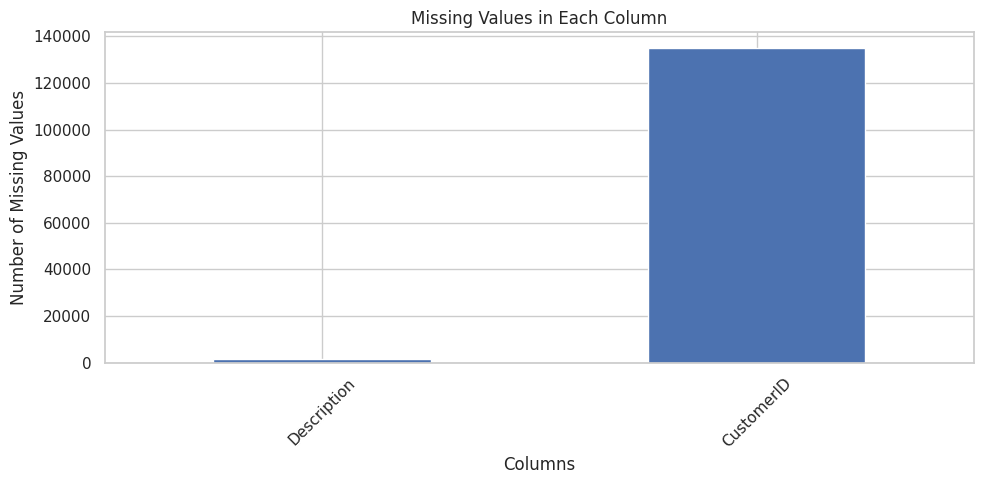

In [15]:
missing_values = df_clean.isnull().sum()

missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(10, 5))

missing_values.plot(kind='bar')

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# Fill missing product descriptions
df_clean['Description'] = (
    df_clean['Description'].fillna('Unknown')
)

# Preserve missing CustomerID values
# CustomerID is not essential for overall sales analysis

print("Missing values after handling:")
print(df_clean.isnull().sum())

Missing values after handling:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [17]:
negative_quantities = (df_clean['Quantity'] < 0).sum()

print("Records with negative quantities:", negative_quantities)

Records with negative quantities: 10587


In [18]:
invalid_prices = (df_clean['UnitPrice'] <= 0).sum()

print("Records with zero or negative prices:", invalid_prices)

Records with zero or negative prices: 2512


In [19]:
cancelled_invoices = df_clean['InvoiceNo'].astype(str).str.startswith('C')

print("Cancelled invoice records:", cancelled_invoices.sum())

Cancelled invoice records: 9251


In [20]:
sales_df = df_clean[
    (~cancelled_invoices) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0)
].copy()

print("Original cleaned records:", len(df_clean))
print("Valid sales records:", len(sales_df))

Original cleaned records: 536641
Valid sales records: 524878


In [21]:
print(df_clean.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [22]:
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)

df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate'],
    errors='coerce'
)

df_clean['Quantity'] = pd.to_numeric(
    df_clean['Quantity'],
    errors='coerce'
)

df_clean['UnitPrice'] = pd.to_numeric(
    df_clean['UnitPrice'],
    errors='coerce'
)

print("Data types corrected successfully!")
print(df_clean.dtypes)

Data types corrected successfully!
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [23]:
cancelled_invoices = (
    df_clean['InvoiceNo'].str.startswith('C')
)

sales_df = df_clean[
    (~cancelled_invoices) &
    (df_clean['Quantity'] > 0) &
    (df_clean['UnitPrice'] > 0) &
    (df_clean['InvoiceDate'].notna())
].copy()

print("Valid sales records:", len(sales_df))

Valid sales records: 524878


In [24]:
sales_df['Revenue'] = (
    sales_df['Quantity'] * sales_df['UnitPrice']
)

print(sales_df[
    ['Description', 'Quantity', 'UnitPrice', 'Revenue']
].head(10))

                           Description  Quantity  UnitPrice  Revenue
0   WHITE HANGING HEART T-LIGHT HOLDER         6       2.55    15.30
1                  WHITE METAL LANTERN         6       3.39    20.34
2       CREAM CUPID HEARTS COAT HANGER         8       2.75    22.00
3  KNITTED UNION FLAG HOT WATER BOTTLE         6       3.39    20.34
4       RED WOOLLY HOTTIE WHITE HEART.         6       3.39    20.34
5         SET 7 BABUSHKA NESTING BOXES         2       7.65    15.30
6    GLASS STAR FROSTED T-LIGHT HOLDER         6       4.25    25.50
7               HAND WARMER UNION JACK         6       1.85    11.10
8            HAND WARMER RED POLKA DOT         6       1.85    11.10
9        ASSORTED COLOUR BIRD ORNAMENT        32       1.69    54.08


In [25]:
columns = ['Quantity', 'UnitPrice']

for col in columns:
    Q1 = sales_df[col].quantile(0.25)
    Q3 = sales_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = sales_df[
        (sales_df[col] < lower) |
        (sales_df[col] > upper)
    ]

    print(f"\n{col}")
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Outliers:", len(outliers))


Quantity
Lower Bound: -14.0
Upper Bound: 26.0
Outliers: 27111

UnitPrice
Lower Bound: -3.0700000000000003
Upper Bound: 8.45
Outliers: 37827


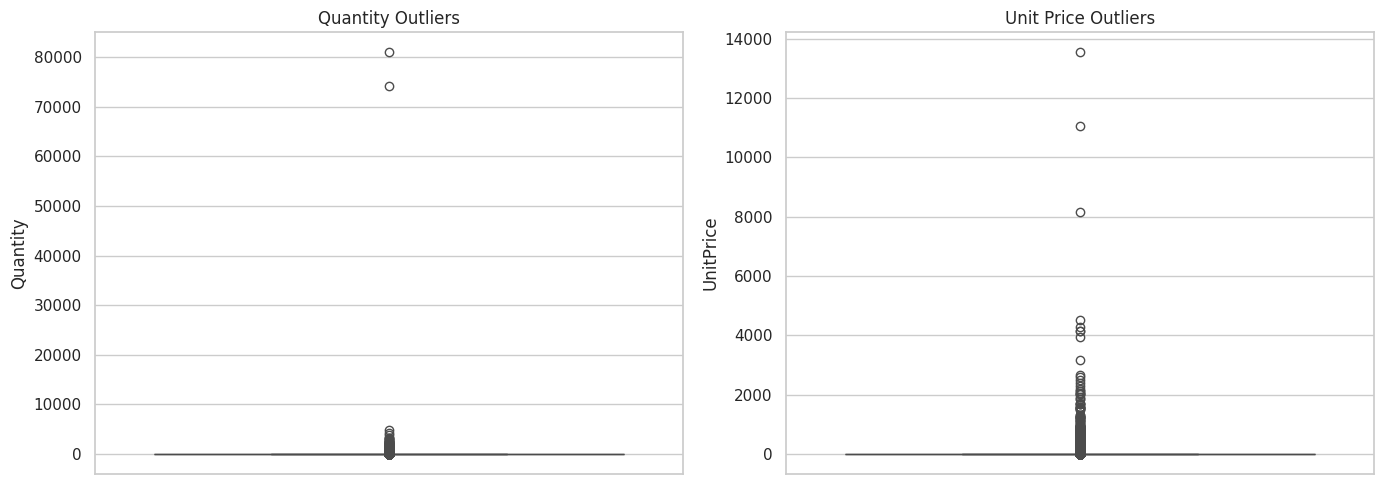

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=sales_df['Quantity'], ax=axes[0])
axes[0].set_title("Quantity Outliers")

sns.boxplot(y=sales_df['UnitPrice'], ax=axes[1])
axes[1].set_title("Unit Price Outliers")

plt.tight_layout()
plt.show()

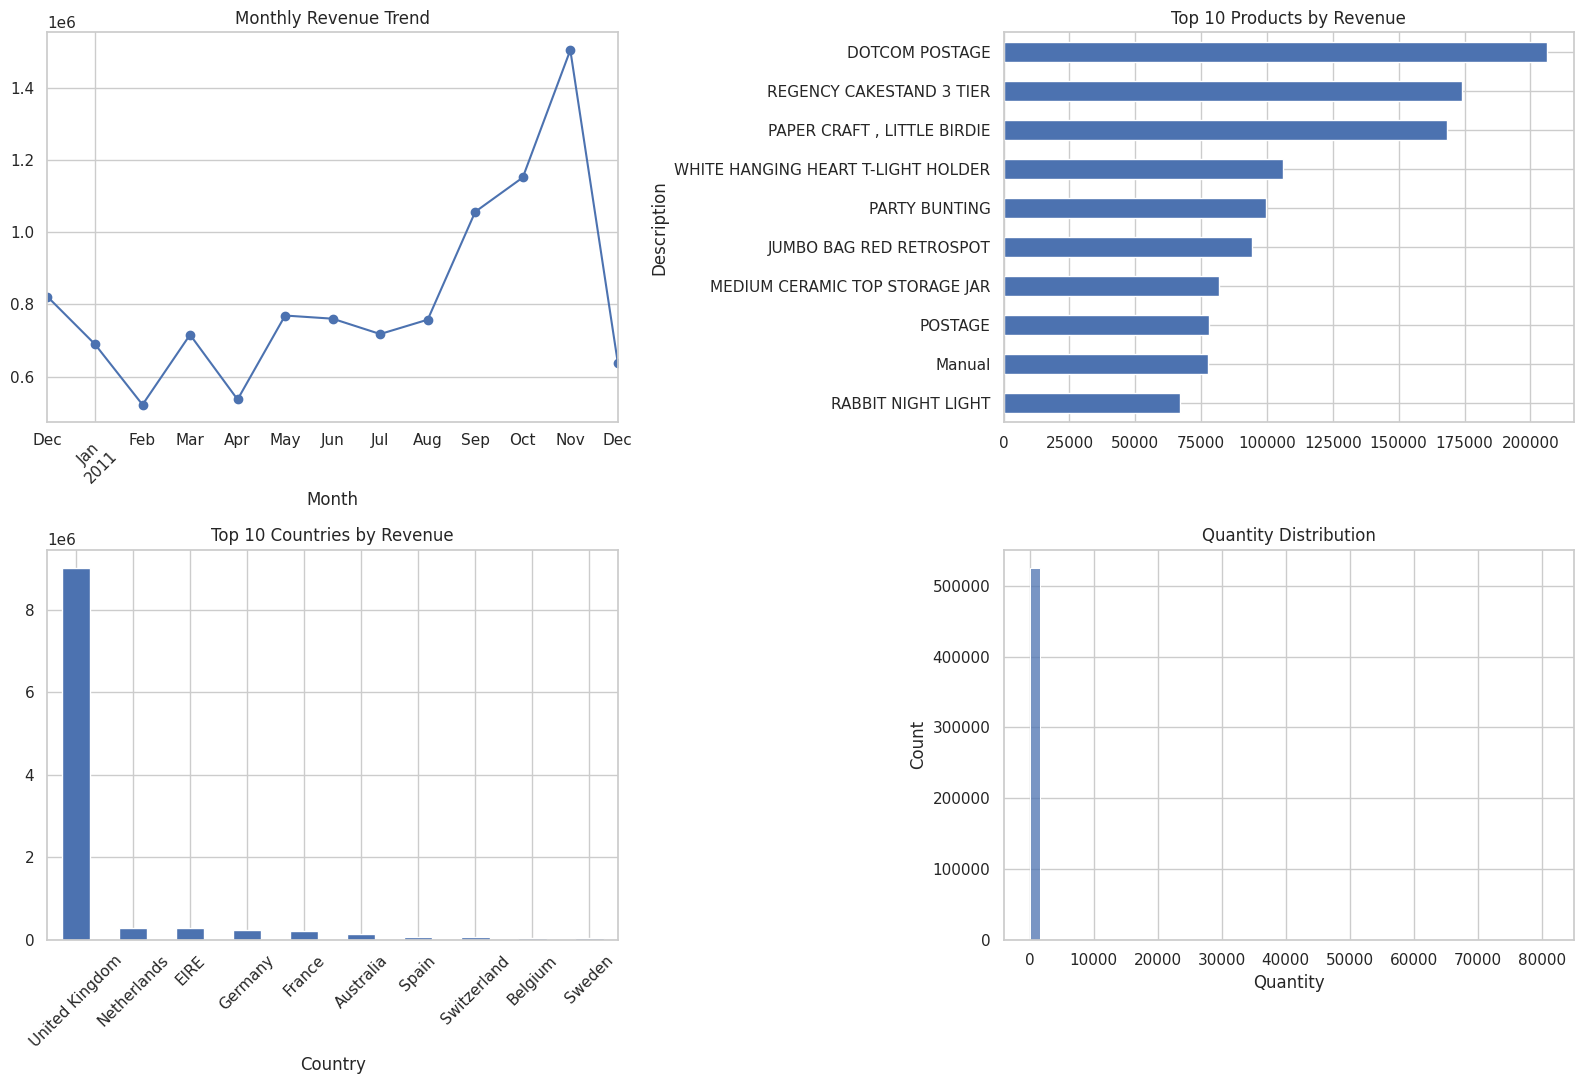

In [27]:
sales_df['Month'] = sales_df['InvoiceDate'].dt.to_period('M')

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Monthly Revenue
monthly_sales = sales_df.groupby('Month')['Revenue'].sum()
monthly_sales.plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Top 10 Products
top_products = sales_df.groupby('Description')['Revenue'].sum().nlargest(10)
top_products.sort_values().plot(kind='barh', ax=axes[0, 1])
axes[0, 1].set_title("Top 10 Products by Revenue")

# 3. Top 10 Countries
country_sales = sales_df.groupby('Country')['Revenue'].sum().nlargest(10)
country_sales.plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title("Top 10 Countries by Revenue")
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Quantity Distribution
sns.histplot(sales_df['Quantity'], bins=50, ax=axes[1, 1])
axes[1, 1].set_title("Quantity Distribution")

plt.tight_layout()
plt.show()

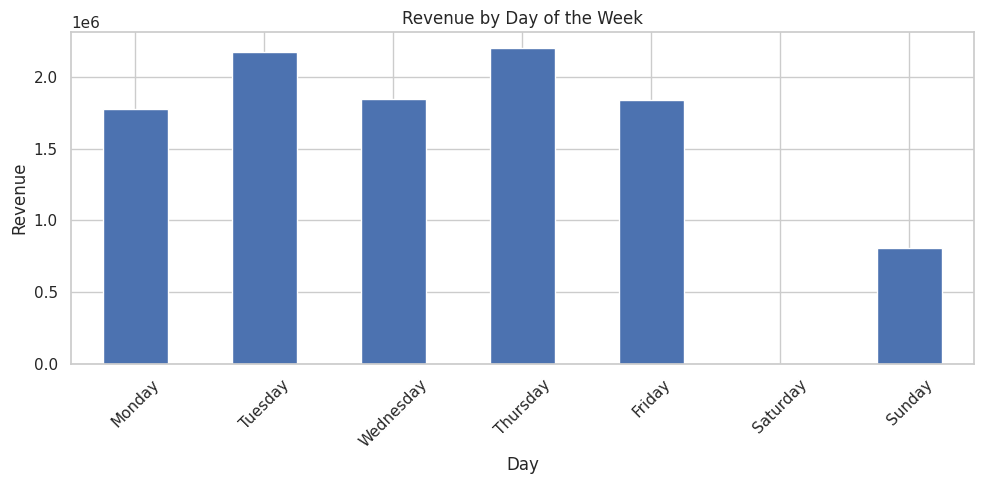

In [28]:
sales_df['Day'] = sales_df['InvoiceDate'].dt.day_name()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_sales = sales_df.groupby('Day')['Revenue'].sum().reindex(day_order)

plt.figure(figsize=(10, 5))

daily_sales.plot(kind='bar')

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

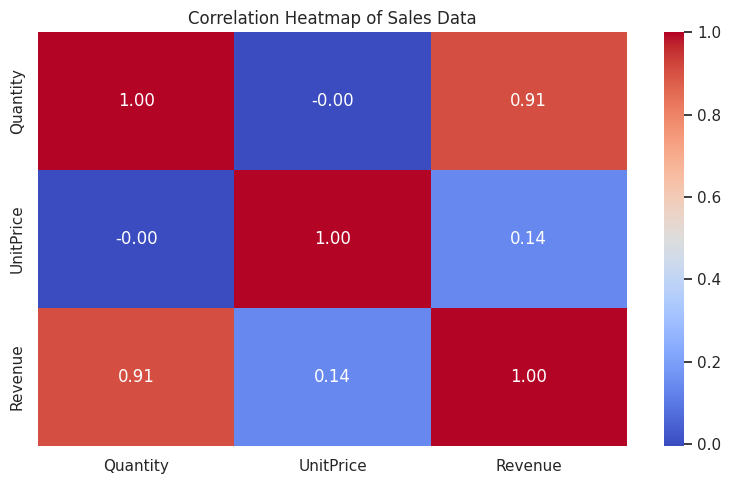

In [29]:
plt.figure(figsize=(8, 5))

correlation = sales_df[
    ['Quantity', 'UnitPrice', 'Revenue']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap of Sales Data")
plt.tight_layout()
plt.show()

In [30]:
print("========== SALES SUMMARY ==========")

print("Total Transactions:", sales_df['InvoiceNo'].nunique())

print("Total Products Sold:", sales_df['Quantity'].sum())

print("Total Revenue:", round(sales_df['Revenue'].sum(), 2))

print("Unique Products:", sales_df['StockCode'].nunique())

print("Unique Customers:", sales_df['CustomerID'].nunique())

print("Countries Covered:", sales_df['Country'].nunique())

print("Average Transaction Revenue:",
      round(sales_df.groupby('InvoiceNo')['Revenue'].sum().mean(), 2))

print("===================================")

========== SALES SUMMARY ==========
Total Transactions: 19960
Total Products Sold: 5572420
Total Revenue: 10642110.8
Unique Products: 3922
Unique Customers: 4338
Countries Covered: 38
Average Transaction Revenue: 533.17


In [31]:
top_country = sales_df.groupby('Country')['Revenue'].sum().idxmax()

top_product = sales_df.groupby('Description')['Revenue'].sum().idxmax()

print("Highest Revenue Country:", top_country)
print("Highest Revenue Product:", top_product)

Highest Revenue Country: United Kingdom
Highest Revenue Product: DOTCOM POSTAGE


In [32]:
sales_df.to_csv(
    "Cleaned_Online_Retail_Data.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [33]:
import os

os.makedirs("visualizations", exist_ok=True)

print("Visualization folder created!")

Visualization folder created!


In [34]:
plt.savefig("visualizations/monthly_sales.png", dpi=300, bbox_inches='tight')


<Figure size 640x480 with 0 Axes>

In [35]:
plt.savefig("visualizations/correlation_heatmap.png", dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [36]:
from google.colab import files

files.download("Cleaned_Online_Retail_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
import os

os.makedirs("reports", exist_ok=True)

print("Report folder created!")

Report folder created!


In [38]:
print("PROJECT SUMMARY")
print("--------------------------")

print("Original records:", len(df))
print("Records after cleaning:", len(df_clean))
print("Valid sales records:", len(sales_df))

print("Total revenue:",
      round(sales_df['Revenue'].sum(), 2))

print("Unique customers:",
      sales_df['CustomerID'].nunique())

print("Unique products:",
      sales_df['StockCode'].nunique())

print("Countries:",
      sales_df['Country'].nunique())

print("Top country:",
      sales_df.groupby('Country')['Revenue'].sum().idxmax())

print("Top product:",
      sales_df.groupby('Description')['Revenue'].sum().idxmax())

PROJECT SUMMARY
--------------------------
Original records: 541909
Records after cleaning: 536641
Valid sales records: 524878
Total revenue: 10642110.8
Unique customers: 4338
Unique products: 3922
Countries: 38
Top country: United Kingdom
Top product: DOTCOM POSTAGE


In [39]:
summary = {
    "Original Records": len(df),
    "Records After Cleaning": len(df_clean),
    "Valid Sales Records": len(sales_df),
    "Total Revenue": round(sales_df['Revenue'].sum(), 2),
    "Unique Customers": sales_df['CustomerID'].nunique(),
    "Unique Products": sales_df['StockCode'].nunique(),
    "Countries": sales_df['Country'].nunique()
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=['Metric', 'Value']
)

summary_df.to_csv(
    "reports/project_summary.csv",
    index=False
)

print("Project statistics saved!")

Project statistics saved!


In [40]:
physical_products = sales_df[
    ~sales_df['Description'].str.contains(
        'POSTAGE', case=False, na=False
    )
]

top_physical_product = (
    physical_products.groupby('Description')['Revenue']
    .sum()
    .idxmax()
)

print("Top Physical Product:", top_physical_product)

Top Physical Product: REGENCY CAKESTAND 3 TIER


In [41]:
import os

folders = [
    "project_submission/data",
    "project_submission/notebooks",
    "project_submission/visualizations",
    "project_submission/reports"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [42]:
sales_df.to_csv(
    "project_submission/data/Cleaned_Online_Retail_Data.csv",
    index=False
)

print("Cleaned dataset saved!")

Cleaned dataset saved!


In [43]:
print("Available project variables:")
print("Cleaned dataset:", sales_df.shape)
print("Visualization folder created:",
      os.path.exists("project_submission/visualizations"))

Available project variables:
Cleaned dataset: (524878, 11)
Visualization folder created: True


In [46]:
import os

visual_dir = "project_submission/visualizations"
os.makedirs(visual_dir, exist_ok=True)

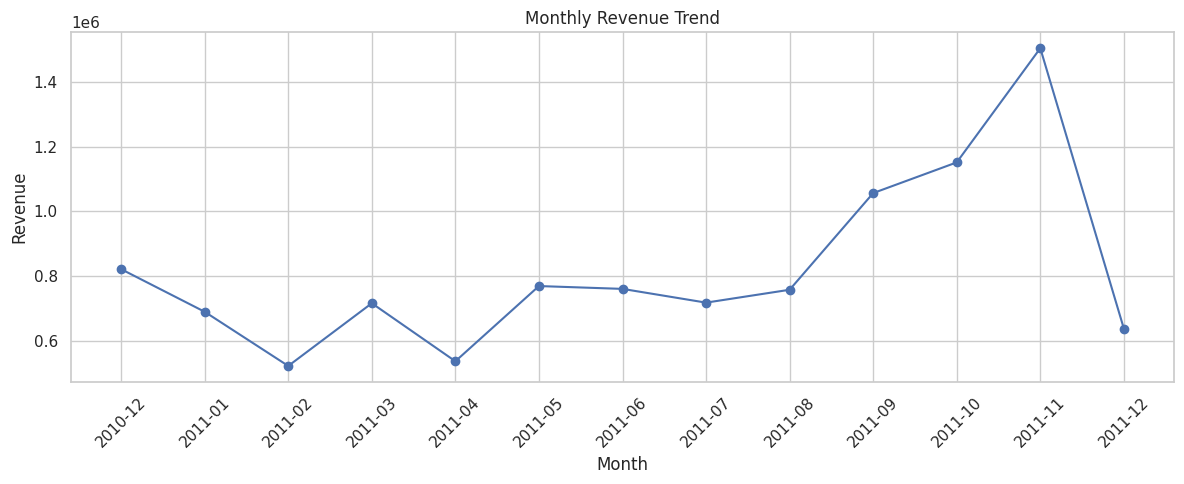

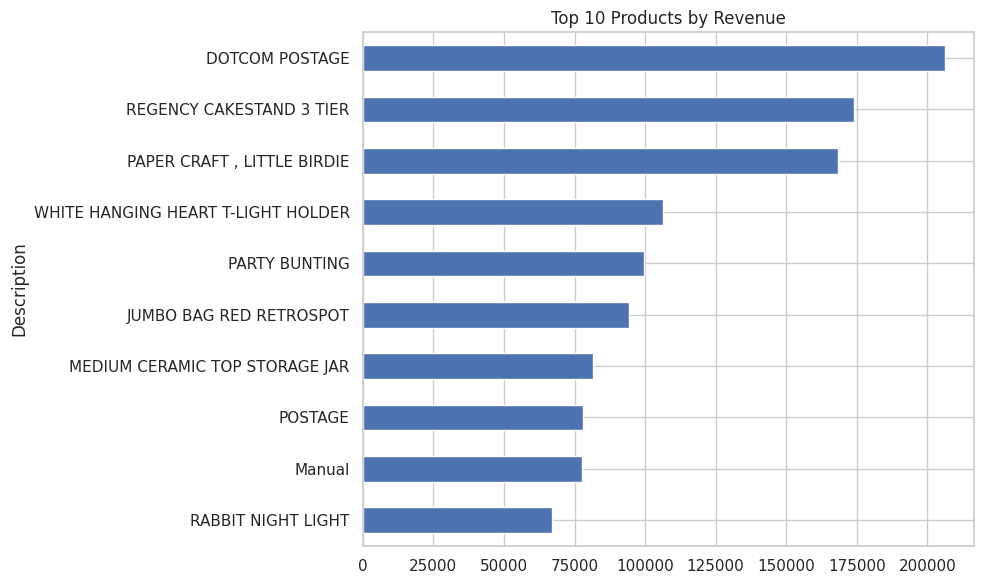

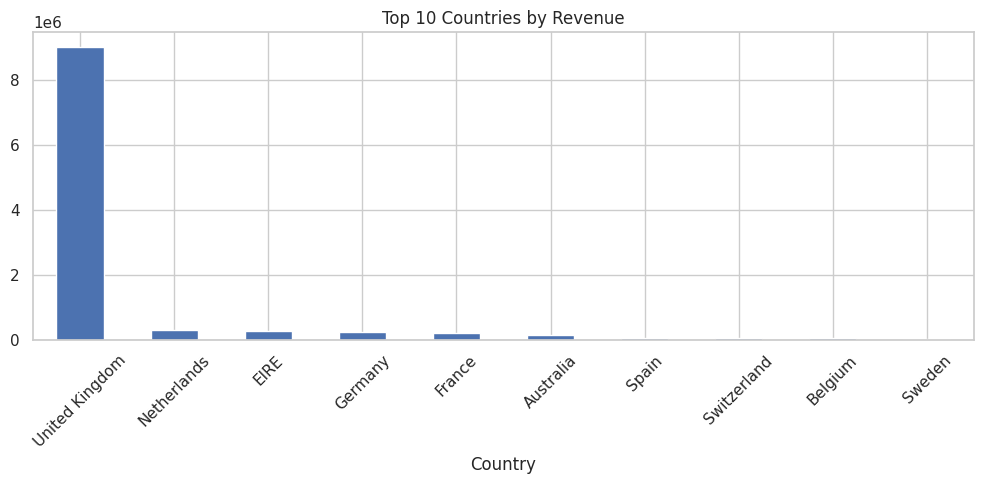

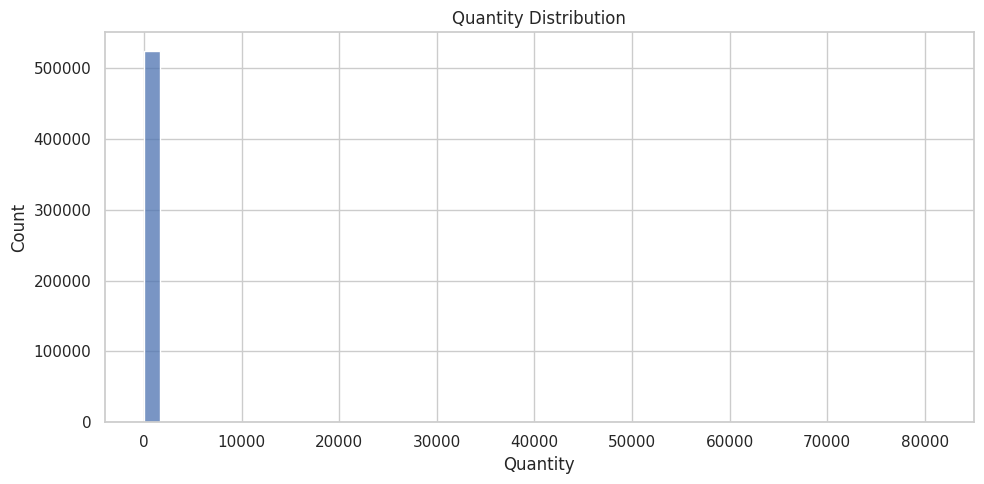

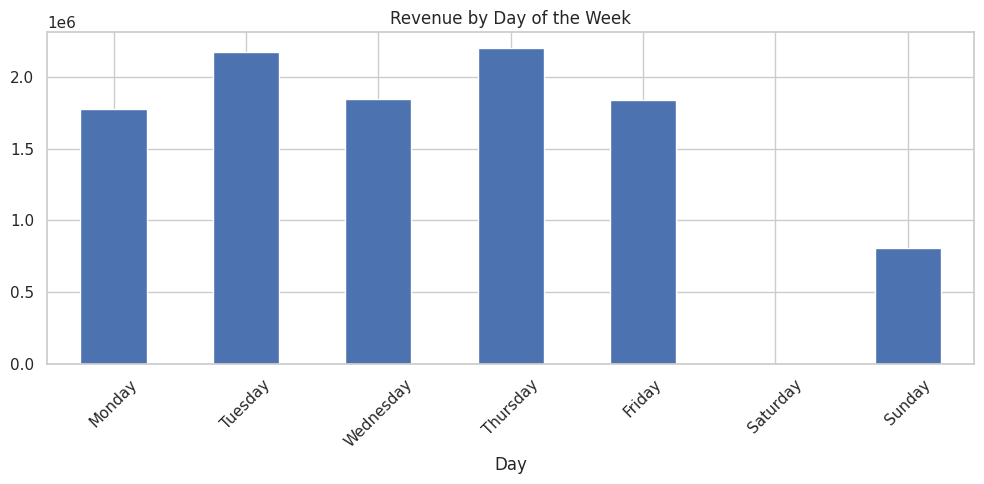

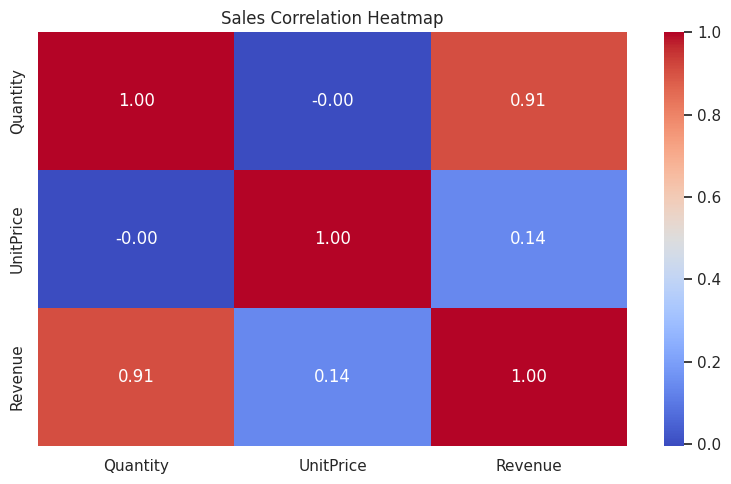

All six visualizations saved successfully!


In [47]:
# 1. Monthly Revenue
monthly_sales = sales_df.groupby(
    sales_df['InvoiceDate'].dt.to_period('M')
)['Revenue'].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values, marker='o')

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{visual_dir}/monthly_sales.png", dpi=300)
plt.show()
plt.close()


# 2. Top 10 Products
top_products = sales_df.groupby(
    'Description'
)['Revenue'].sum().nlargest(10)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind='barh')

plt.title("Top 10 Products by Revenue")
plt.tight_layout()
plt.savefig(f"{visual_dir}/top_products.png", dpi=300)
plt.show()
plt.close()


# 3. Top 10 Countries
country_sales = sales_df.groupby(
    'Country'
)['Revenue'].sum().nlargest(10)

plt.figure(figsize=(10, 5))
country_sales.plot(kind='bar')

plt.title("Top 10 Countries by Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{visual_dir}/country_sales.png", dpi=300)
plt.show()
plt.close()


# 4. Quantity Distribution
plt.figure(figsize=(10, 5))
sns.histplot(sales_df['Quantity'], bins=50)

plt.title("Quantity Distribution")
plt.tight_layout()
plt.savefig(f"{visual_dir}/quantity_distribution.png", dpi=300)
plt.show()
plt.close()


# 5. Daily Revenue
sales_df['Day'] = sales_df['InvoiceDate'].dt.day_name()

day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_sales = sales_df.groupby('Day')['Revenue'].sum().reindex(day_order)

plt.figure(figsize=(10, 5))
daily_sales.plot(kind='bar')

plt.title("Revenue by Day of the Week")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{visual_dir}/daily_sales.png", dpi=300)
plt.show()
plt.close()


# 6. Correlation Heatmap
plt.figure(figsize=(8, 5))

correlation = sales_df[
    ['Quantity', 'UnitPrice', 'Revenue']
].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Sales Correlation Heatmap")
plt.tight_layout()
plt.savefig(f"{visual_dir}/correlation_heatmap.png", dpi=300)
plt.show()
plt.close()

print("All six visualizations saved successfully!")

In [48]:
print(os.listdir(visual_dir))

['correlation_heatmap.png', 'daily_sales.png', 'monthly_sales.png', 'country_sales.png', 'quantity_distribution.png', 'top_products.png']


In [49]:
for root, dirs, files_list in os.walk("project_submission"):
    print(root, ":", files_list)

project_submission : []
project_submission/data : ['Cleaned_Online_Retail_Data.csv']
project_submission/reports : []
project_submission/visualizations : ['correlation_heatmap.png', 'daily_sales.png', 'monthly_sales.png', 'country_sales.png', 'quantity_distribution.png', 'top_products.png']
project_submission/notebooks : []
